# CT Scan Reconstructor — Simple Demo

Choose one of two simple 8×8 inputs:

- **Square** — easiest input
- **Phantom** — simple CT-style object with different density levels

The remaining steps are the same:

**Image → x → A → b = Ax → Rank/Nullity → Least Squares → Reconstruction**


In [4]:
import numpy as np
import matplotlib.pyplot as plt

## Step 1 — Choose the input

Change only this line:

`choice = "square"`  
or  
`choice = "phantom"`


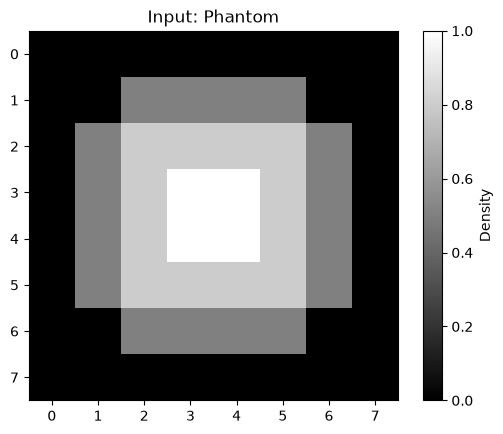

[[0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.5 0.5 0.5 0.5 0.  0. ]
 [0.  0.5 0.8 0.8 0.8 0.8 0.5 0. ]
 [0.  0.5 0.8 1.  1.  0.8 0.5 0. ]
 [0.  0.5 0.8 1.  1.  0.8 0.5 0. ]
 [0.  0.5 0.8 0.8 0.8 0.8 0.5 0. ]
 [0.  0.  0.5 0.5 0.5 0.5 0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  0. ]]


In [5]:
choice = "phantom"   # change to "square" if needed

square = np.zeros((8,8))
square[2:6, 2:6] = 1

phantom = np.zeros((8,8))
phantom[1:7, 2:6] = 0.5
phantom[2:6, 1:7] = 0.5
phantom[2:6, 2:6] = 0.8
phantom[3:5, 3:5] = 1.0

image = square if choice == "square" else phantom

plt.imshow(image, cmap="gray", vmin=0, vmax=1)
plt.title("Input: " + choice.title())
plt.colorbar(label="Density")
plt.show()

print(image)

### What the values mean
- **0** → black / low density
- **0.5** → grey
- **0.8** → lighter grey
- **1** → white / high density

The phantom uses different grey levels to represent different densities.


## Step 2 — Convert image to vector x

An 8×8 image has **64 pixels**.  
`flatten()` writes them as one vector.


In [ ]:
x = image.flatten()

print("Image shape =", image.shape)
print("x shape =", x.shape)

## Step 3 — Build measurement matrix A

We take simple line measurements in four directions:
- horizontal
- vertical
- diagonal ↘
- diagonal ↙


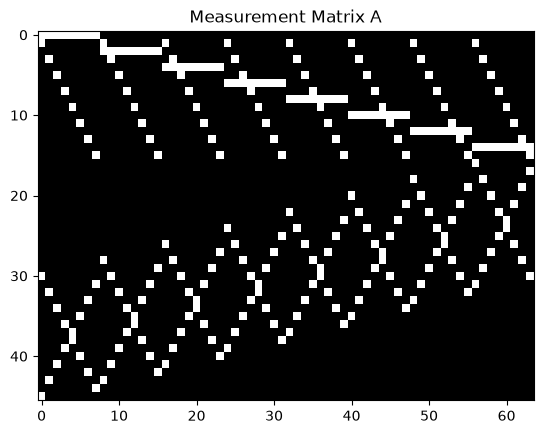

A shape = (46, 64)


In [6]:
A = []

for i in range(8):
    h = np.zeros((8,8)); h[i,:] = 1
    v = np.zeros((8,8)); v[:,i] = 1
    A += [h.flatten(), v.flatten()]

for k in range(-7,8):
    d = np.eye(8, k=k)
    A += [d.flatten(), np.fliplr(d).flatten()]

A = np.array(A)

plt.imshow(A, cmap="gray", aspect="auto")
plt.title("Measurement Matrix A")
plt.show()

print("A shape =", A.shape)

## Step 4 — Calculate measurements b = Ax

Each value in **b** is the sum of densities along one scan line.


In [7]:
b = A @ x

plt.bar(range(1, len(b)+1), b)
plt.title("Measurements b")
plt.xlabel("Measurement")
plt.ylabel("Line sum")
plt.show()

print("b shape =", b.shape)

NameError: name 'x' is not defined

## Step 5 — Rank and Nullity

- **Rank** = independent information available
- **Nullity** = information not uniquely determined


In [8]:
rank = np.linalg.matrix_rank(A)
nullity = 64 - rank

print("Rank =", rank)
print("Nullity =", nullity)

Rank = 39
Nullity = 25


## Step 6 — Least-Squares Reconstruction

Least squares estimates the 64 pixel values using only **A** and **b**.


In [9]:
x_est = np.linalg.lstsq(A, b, rcond=None)[0]
reconstructed = x_est.reshape(8,8)

plt.figure(figsize=(7,3))

plt.subplot(1,2,1)
plt.imshow(image, cmap="gray", vmin=0, vmax=1)
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(reconstructed, cmap="gray", vmin=0, vmax=1)
plt.title("Reconstructed")
plt.axis("off")

plt.tight_layout()
plt.show()

NameError: name 'b' is not defined

## Final Note

For the **square**, a 0.5 threshold can be used because it contains only 0 and 1.

For the **phantom**, we keep the grey values because they represent different density levels.
